In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import scipy

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/ioai-philippines-2026-round-2-semi-finals/ioai_qc_train.csv
/kaggle/input/competitions/ioai-philippines-2026-round-2-semi-finals/SUBMISSION_FINAL_INT.csv
/kaggle/input/competitions/ioai-philippines-2026-round-2-semi-finals/TEST_FINAL_INT.csv


is_clear            -0.440788
surface_pressure    -0.262997
pressure_msl_lag3   -0.251632
pressure_msl        -0.246964
temp_diff_1h        -0.185228
                       ...   
is_rain              0.830158
rain                 0.899235
precipitation        1.000000
snowfall                  NaN
snow_depth                NaN
Length: 63, dtype: float64


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


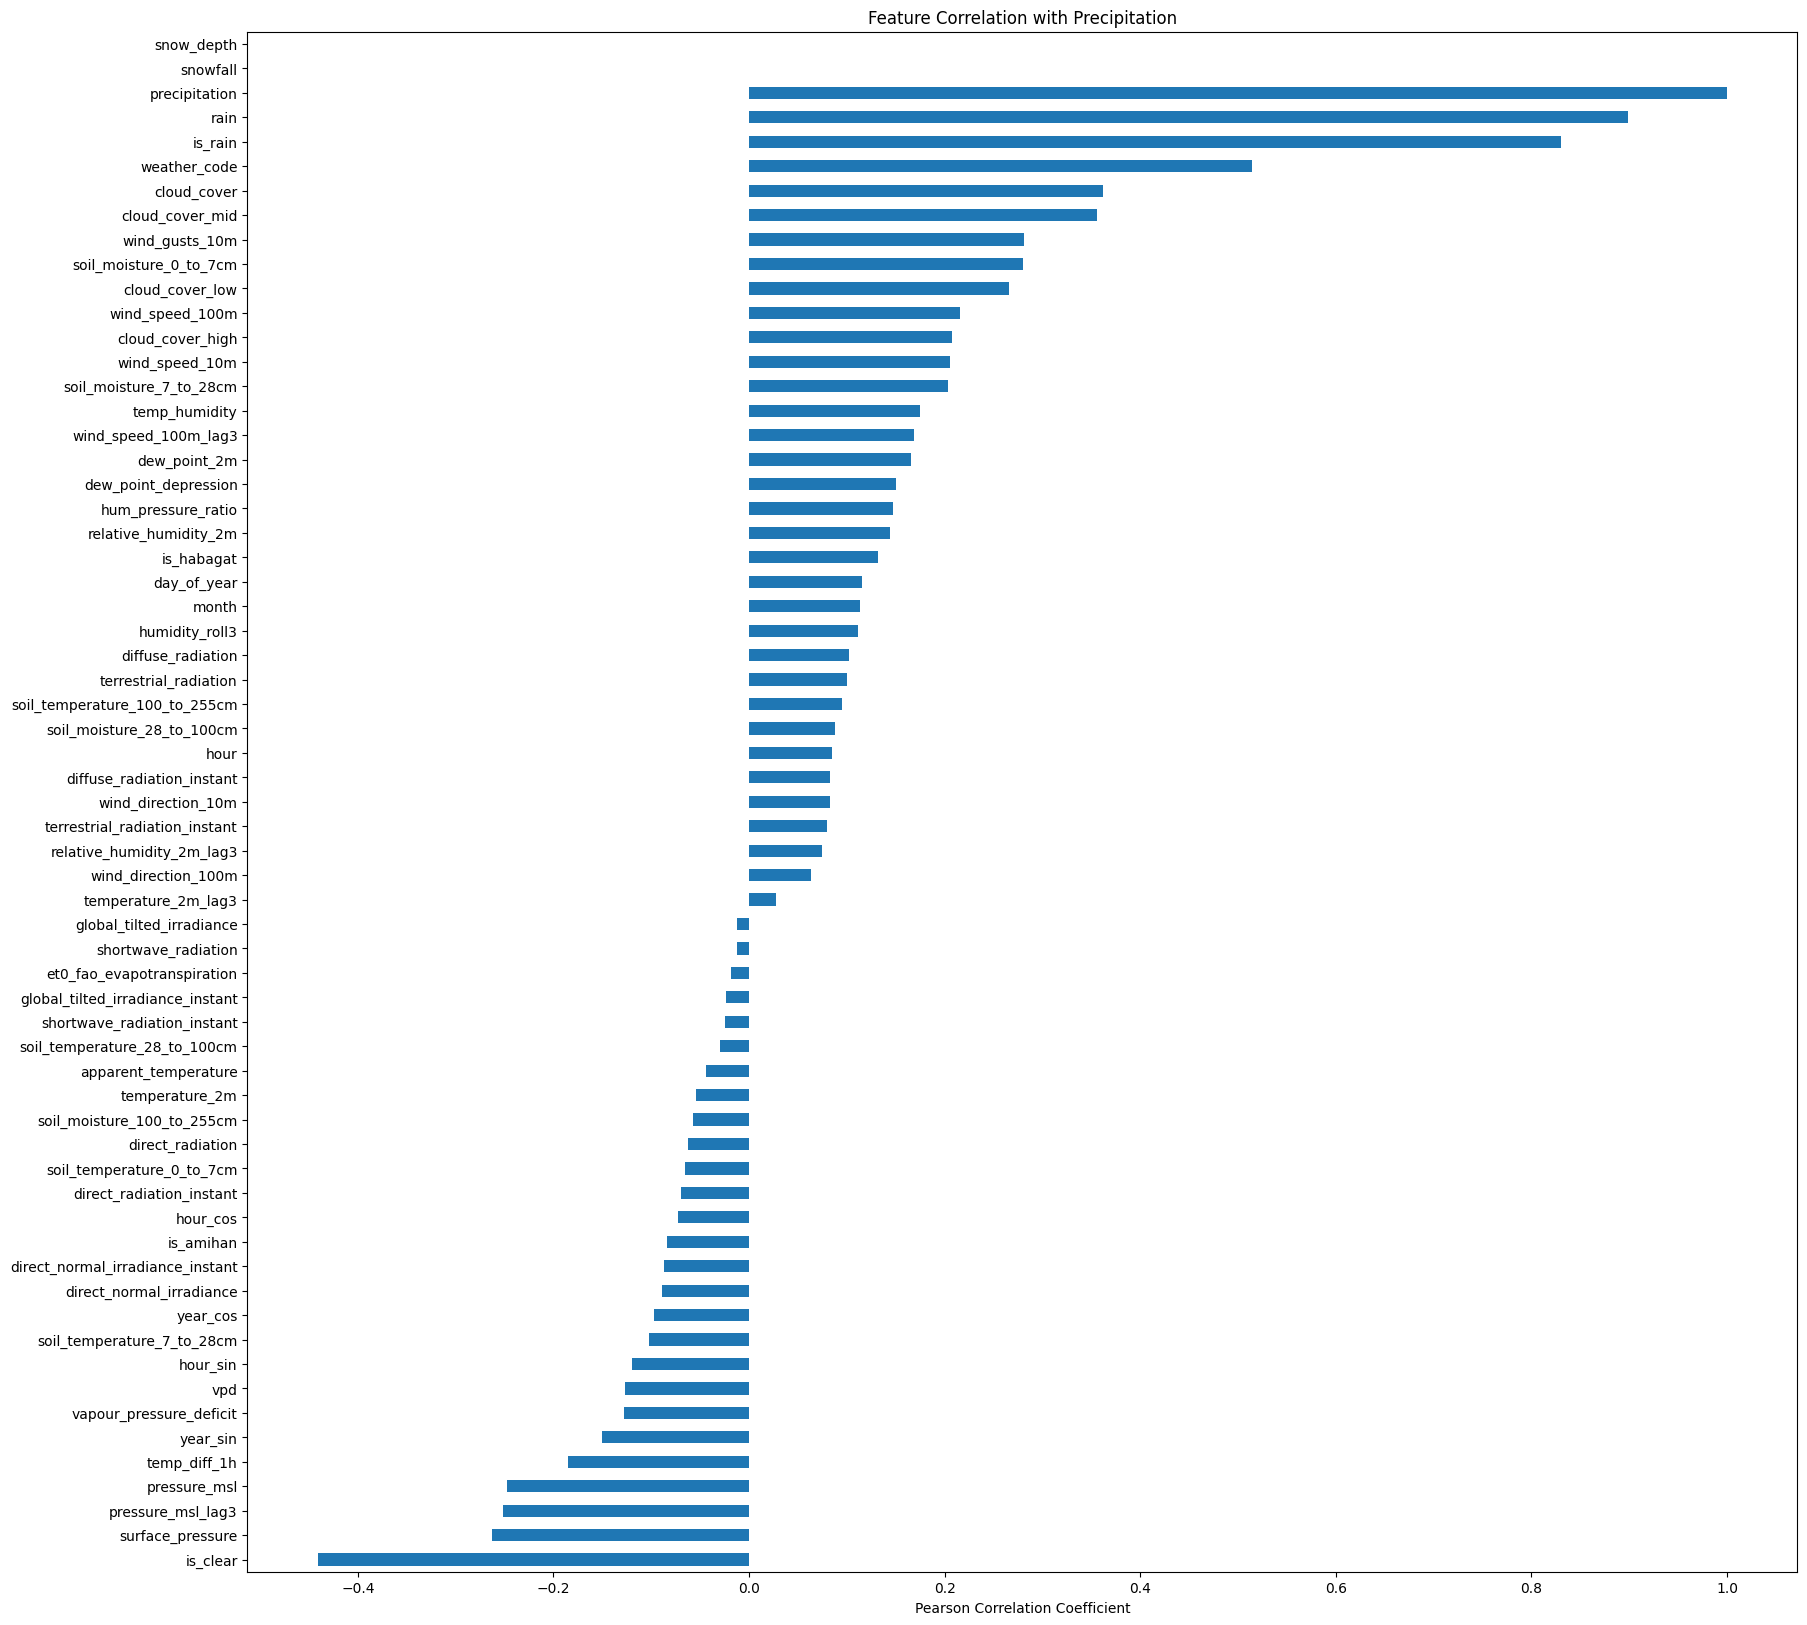

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns


matrix = train.corrwith(train[precip], numeric_only=True)
precip_correlations = matrix.sort_values(ascending=True)
print(precip_correlations)

plt.figure(figsize=(20,20))
precip_correlations.sort_values().plot(kind='barh')
plt.title("Feature Correlation with Precipitation")
plt.xlabel("Pearson Correlation Coefficient")
plt.show()

In [97]:
# 1. SETUP & DATA LOADING
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

# Load the datasets
train = pd.read_csv('/kaggle/input/competitions/ioai-philippines-2026-round-2-semi-finals/ioai_qc_train.csv')
test = pd.read_csv('/kaggle/input/competitions/ioai-philippines-2026-round-2-semi-finals/TEST_FINAL_INT.csv')
sample_sub = pd.read_csv('/kaggle/input/competitions/ioai-philippines-2026-round-2-semi-finals/ioai_qc_train.csv')
humidity = 'relative_humidity_2m'
pressure = 'pressure_msl'
temp = 'temperature_2m'
precip = 'precipitation'
longwind = 'wind_speed_100m'
shortgusts = 'wind_gusts_10m'
soil_moisture_top = 'soil_moisture_0_to_7cm'
soil_moisture_bottom = 'soil_moisture_7_to_28cm'

# 2. DATA CLEANING (Syllabus: Handling Sensor Noise)
# Example: Fix the 999% humidity sensor error mentioned in the syllabus
train[humidity] = train[humidity].apply(lambda x: np.nan if x > 100 else x)
test[humidity] = test[humidity].apply(lambda x: np.nan if x > 100 else x)
train[humidity] = train[humidity].interpolate(method='linear')
test[humidity] = test[humidity].interpolate(method='linear')
train[precip] = train[precip].clip(upper=train[precip].quantile(0.995))

# 3. FEATURE ENGINEERING (Time-Series Patterns)
def create_features(df):
    df = df.copy()
    df['datetime'] = pd.to_datetime(df['datetime'], format='mixed')
    df['hour'] = df['datetime'].dt.hour
    df['day_of_year'] = df['datetime'].dt.dayofyear
    df['month'] = df['datetime'].dt.month

    df['year_sin'] = np.sin(2*np.pi*df['day_of_year']/365)
    df['year_cos'] = np.cos(2*np.pi*df['day_of_year']/365)

    df['hour_sin'] = np.sin(2*np.pi*df['hour']/24)
    df['hour_cos'] = np.cos(2*np.pi*df['hour']/24)

    df['is_habagat'] = df['month'].isin(range(6,10)).astype(int)
    df['is_amihan'] = df['month'].isin([11,12,1,2]).astype(int)

    df['temp_humidity'] = df[temp] * df[humidity]
    df['dew_point_depression'] = df[temp] - ((100 - df[humidity])/5)
    df['hum_pressure_ratio'] = df[humidity] / df[pressure]
    df['temp_diff_1h'] = df[temp].diff(1)

    # WEATHER-CODE HANDLING
    df['is_clear'] = df['weather_code'].isin(range(4)).astype(int)
    df['is_rain'] = df['weather_code'].isin(range(61,66)).astype(int)
        

    # LAGGED FEATURES
    for col in [temp, humidity, pressure, longwind]:
        df[f'{col}_lag3'] = df[col].shift(3)
    df['humidity_roll3'] = df[humidity].rolling(window=3).mean()

    # VALUE CLEANING
    df[longwind] = df[longwind].clip(lower=0)
    pressure_low = df[pressure].quantile(0.005)
    pressure_high = df[pressure].quantile(0.995)
    df[pressure] = df[pressure].clip(lower=pressure_low, upper=pressure_high) 

    # VAPOR PRESSURE DEFICIT
    saturation = 0.61078 * np.exp((17.27*df[temp])/(df[temp]+237.3))
    actual = saturation * (df[humidity]/100.0)
    df['vpd'] = saturation - actual

    # FILL OTHER NaNs
    df = df.ffill().fillna(df.median(numeric_only=True))
    
    return df

train = create_features(train)
test = create_features(test)

# 4. MODEL TRAINING
# Define features and target
features = [pressure, longwind, 'weather_code', 'vpd', 'is_clear', 'is_rain', soil_moisture_top, 
            soil_moisture_bottom, shortgusts, 'cloud_cover', 'cloud_cover_mid',
            'hour_sin', 'hour_cos', 'year_sin', 'year_cos', 'is_habagat', 'is_amihan', 
            'temp_humidity', 'humidity_roll3', 'dew_point_depression',
            'hum_pressure_ratio', 'temp_diff_1h'
            , f'{humidity}_lag3', f'{pressure}_lag3', f'{longwind}_lag3']
X_train = train[features]
y_train = np.log1p(train[precip])

# Simple XGBoost Baseline
model = XGBRegressor(objective="reg:absoluteerror", n_estimators=2000, learning_rate=0.015, max_depth=6, random_state=42, reg_alpha=10.0, reg_lambda=1.0, tree_method='hist')
model.fit(X_train, y_train)

# 5. PREDICTION & SUBMISSION (CRITICAL: Using the 'id' column)
# Generate predictions for 2023
test_preds = np.expm1(model.predict(test[features]))

# Ensure predictions are not negative (rainfall can't be negative)
test_preds = np.maximum(0, test_preds)
test_preds[test_preds < 0.1] = 0
test_preds = np.round(test_preds, 1)

# Create the final submission file
# We use the 'id' column exactly as provided in the test set
submission = pd.DataFrame({
    'id': test['id'],
    'precipitation': test_preds
})

# Save to CSV
submission.to_csv('submission.csv', index=False)
print("Submission file 'submission.csv' created successfully with integer IDs!")

Submission file 'submission.csv' created successfully with integer IDs!


In [96]:
# FOLD 1

train['year'] = train['datetime'].dt.year
train_subset = train[train['year'] < 2022].copy()
val_subset = train[train['year'] == 2022].copy()
model.fit(train_subset[features], np.log1p(train_subset[precip]))
val_preds = np.expm1(model.predict(val_subset[features]))
val_preds = np.maximum(0, val_preds)
val_preds[val_preds < 0.08] = 0
val_preds = np.round(val_preds, 1)
val_mae = mean_absolute_error(val_subset[precip], val_preds)
print(f'Fold 1 MAE: {val_mae}')

Fold 1 MAE: 0.057636987158696945
